# In-hospital Death: reproducible experiment

## Declaration on Use of GAI
OpenAI Codex assisted with the 17 October 2026 repository audit, executable notebook,
path and bootstrap fixes, documentation and verification. Code, tables and figures below
are executed against the submitted data and saved model. AI did not supply patient data
or synthetic performance results. See [GAI_DECLARATION.md](docs/GAI_DECLARATION.md) and
[AI_USE_LOG.md](docs/AI_USE_LOG.md) for scope, errors and corrections. Earlier tools and each
member's use cannot be established from these files and require the team's factual declaration.

This repository covers **in-hospital mortality only**. It preserves the reviewed
**11,833-stay / 1,474-feature / XGBoost** experiment. Task numbering changed in the later
combined presentation; the clinical outcome, rather than the task number, identifies this work.
The later 12,000-stay CatBoost experiment and SOFA forecasting are outside this package.

## 1. Clinical question and execution
At the 48-hour ICU landmark, predict final `In-hospital_death` using observations in
**[0, 48 h)**. This is a binary retrospective research task. The source cohort already
requires an ICU stay of at least 48 hours; applicability to earlier deaths is limited.

The goal is to compare random scores, single-variable baselines, SAPS-I/SOFA,
eight-feature logistic regression, and gradient-boosted trees. AUPRC is clinically useful
with 14.4% mortality; AUROC describes ranking. **The historical search and model selection
actually optimised AUROC**; AUPRC is also reported, not retrospectively substituted as
its selection objective. Sensitivity, PPV, specificity and min(Se,PPV) use a validation
threshold targeting recall 0.80.

Run all cells in the pinned Python 3.11 environment. Default execution refits the inexpensive
L3 models and replays the saved L4 model on CPU; it does not redo the GPU search.
Set `RETRAIN_L4` or `RUN_FULL_SEARCH` below only to run new development fits.
Default outputs are published under `results/notebook/`, `results/figures/notebook/` and
`models/notebook/`. Optional search/refit outputs use the ignored `artifacts/notebook/` directory.
Historical L4 results and the frozen input snapshot retain their existing paths.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Locate the project root from the current directory or an ancestor.
HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents]
            if (p / 'data' / 'manifest.sha256').is_file())
sys.path.insert(0, str(ROOT / 'code'))
from data import load_data, get_split, get_feature_names
from metrics import compute_metrics, bootstrap_ci, find_threshold_for_recall
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import joblib

SEED = 42
N_BOOTSTRAP = 1000
RETRAIN_L4 = False
RUN_FULL_SEARCH = False
RESULT_DIR = ROOT / 'results' / 'notebook'
TABLE_DIR = RESULT_DIR / 'tables'
FIGURE_DIR = ROOT / 'results' / 'figures' / 'notebook'
MODEL_DIR = ROOT / 'models' / 'notebook'
SCRATCH_DIR = ROOT / 'artifacts' / 'notebook'
for directory in [RESULT_DIR, TABLE_DIR, FIGURE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 14)
versions = {'python': platform.python_version(), **{p: importlib.metadata.version(p) for p in
    ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'catboost', 'scipy', 'matplotlib', 'joblib']}}
display(pd.Series(versions, name='executed environment').to_frame())

,executed environment
python,3.11.7
numpy,1.26.4
pandas,2.1.4
scikit-learn,1.2.2
xgboost,3.2.0
catboost,1.2.10
scipy,1.11.4
matplotlib,3.8.0
joblib,1.3.2


## 2. Data provenance and integrity
The public source is PhysioNet / Computing in Cardiology Challenge 2012. All three
released sets were pooled. The reviewed experiment excludes 167 negative-length-of-stay
records, leaving 11,833 stays and 1,707 deaths. These exclusions are a historical cohort
choice and a limitation, not a requirement of mortality prediction.

The processed snapshot is bundled, so model replay needs no download or credentials.
SHA-256 checks below reject altered artifacts before modelling. The separate preprocessing
notebook audits the copied preprocessing outputs; optional raw rebuilding is documented in
`preprocessing/README.md`. Rebuilding with a different raw release or cleaning version is
a new experiment and must not silently replace this frozen snapshot.

In [2]:
checks = []
for line in (ROOT / 'data' / 'manifest.sha256').read_text().splitlines():
    expected, name = line.split(maxsplit=1)
    path = ROOT / 'data' / name.strip()
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    checks.append({'file': path.name, 'sha256_match': actual == expected})
assert all(r['sha256_match'] for r in checks), 'Frozen snapshot hash mismatch'
display(pd.DataFrame(checks))
labels, X_raw, X_imputed = load_data()
features = get_feature_names()
assert len(labels) == len(X_raw) == 11833 and len(features) == 1474
assert labels.RecordID.is_unique and X_raw.RecordID.is_unique
assert set(labels.RecordID) == set(X_raw.RecordID)
assert labels['In-hospital_death'].sum() == 1707
for split in ['train', 'validation', 'test']:
    assert set(X_imputed[split].RecordID) == set(labels.loc[labels.split.eq(split), 'RecordID'])
forbidden = ['in_hospital_death', 'saps_i', 'sofa', 'survival', 'length_of_stay', 'recordid']
assert not [f for f in features if any(t in f.lower().replace('-', '_') for t in forbidden)]
cohort = labels.groupby('split')['In-hospital_death'].agg(['size', 'sum', 'mean'])
cohort.columns = ['stays', 'deaths', 'prevalence']
display(cohort.loc[['train', 'validation', 'test']])

,file,sha256_match
0,X_test_imputed.csv.gz,True
1,X_train_imputed.csv.gz,True
2,X_validation_imputed.csv.gz,True
3,feature_dictionary.csv,True
4,feature_missingness.csv,True
5,independent_verification.json,True
6,labels_and_baselines.csv,True
7,labels_and_splits.csv,True
8,parameter_distributions.csv,True
9,patient_features_48h_inclusive_affected_rows.c...,True


,stays,deaths,prevalence
split,,,
train,8283,1195,0.144271
validation,1775,256,0.144225
test,1775,256,0.144225


The fixed outcome-stratified split uses seed **20260907** and proportions 70/15/15:
8,283 training stays, 1,775 validation stays, 1,775 test stays. Estimator and bootstrap
seeds are separately fixed at 42. Every fit uses training rows; validation chooses the
operating threshold and the historical L4 candidate. Test is used below to reproduce
already-declared models, never to choose new features or tune a new model.

Only stay identifiers are available. Multiple stays from the same patient cannot be
identified, so this is stay-level internal validation, not verified patient-independent validation.

In [3]:
# Align unimputed rows by RecordID, preserving the same order as the frozen split files.
raw_index = X_raw.set_index('RecordID')
y_by_split = {}; raw_by_split = {}; imputed_by_split = {}
for split in ['train', 'validation', 'test']:
    Xi, yi = get_split(split)
    ids = X_imputed[split].RecordID
    raw_by_split[split] = raw_index.loc[ids, features].reset_index(drop=True)
    imputed_by_split[split] = Xi.reset_index(drop=True)
    y_by_split[split] = yi.to_numpy()
assert len(set(X_imputed['train'].RecordID) & set(X_imputed['test'].RecordID)) == 0

## 3. Exploratory data analysis (training rows)
Inspect missingness, age, neurological status and renal measures before looking at test
performance. Irregular sampling creates informative missingness: “not measured” need not
mean normal. The next plots use training rows only. Outcome relationships are descriptive
associations and cannot establish causes or treatment effects.

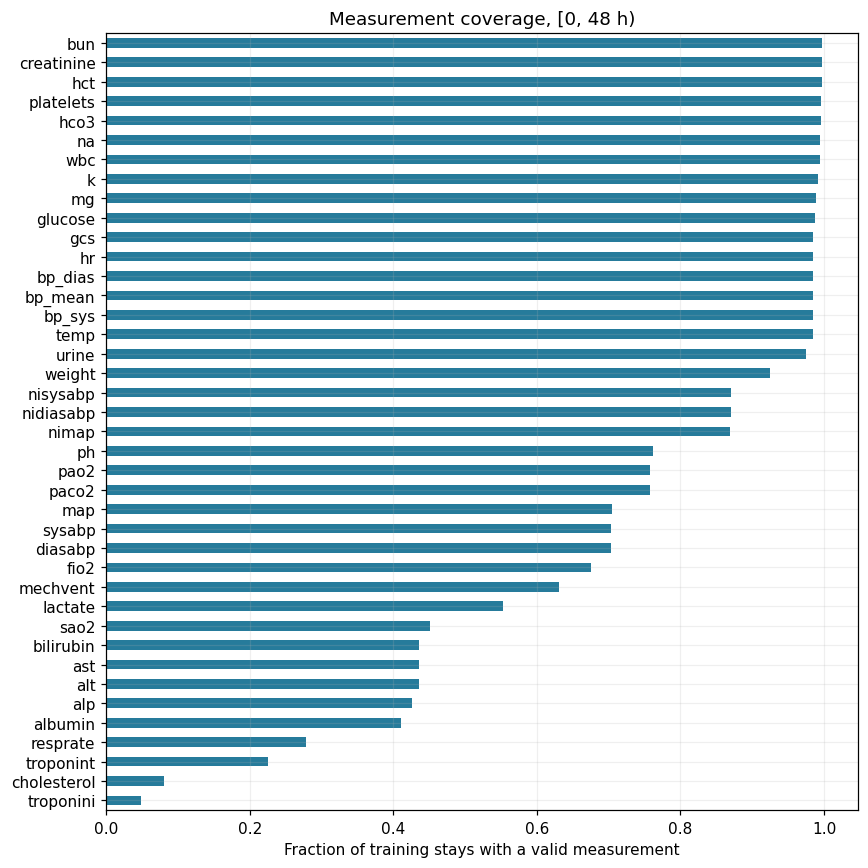

,static_age_years,gcs__0_48h__last,bun__0_48h__max,urine__0_48h__total,lactate__0_48h__max
count,8268.00,8161.00,8262.00,8080.00,4578.00
mean,64.61,12.38,29.12,4140.58,3.14
std,17.13,3.65,22.79,2336.96,2.64
min,18.00,3.00,2.00,0.00,0.40
25%,53.00,10.00,15.00,2504.25,1.50
50%,67.00,15.00,22.00,3865.00,2.30
75%,78.00,15.00,35.00,5445.00,3.70
max,90.00,15.00,209.00,23985.00,27.60


In [4]:
train = raw_by_split['train']
y_train = y_by_split['train']
coverage = pd.Series({f.split('__')[0]: train[f].mean()
    for f in features if f.endswith('__0_48h__measured')}).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
coverage.plot.barh(ax=ax, color='#267b9b')
ax.set(xlabel='Fraction of training stays with a valid measurement', title='Measurement coverage, [0, 48 h)')
fig.tight_layout(); fig.savefig(FIGURE_DIR / 'eda_measurement_coverage.png'); plt.show()
display(train[['static_age_years','gcs__0_48h__last','bun__0_48h__max',
               'urine__0_48h__total','lactate__0_48h__max']].describe().round(2))

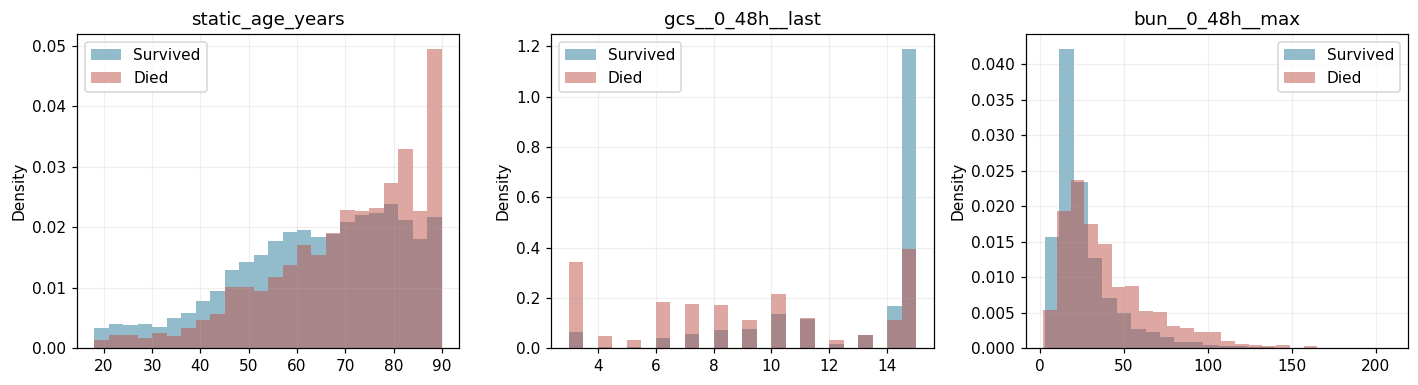

,training missing fraction
cholesterol__24_48h__slope_per_hour,0.999879
cholesterol__0_24h__slope_per_hour,0.997465
cholesterol__0_48h__slope_per_hour,0.996137
troponini__24_48h__slope_per_hour,0.992998
cholesterol__24_48h__delta,0.989738
cholesterol__24_48h__mean,0.989738
cholesterol__24_48h__max,0.989738
cholesterol__24_48h__median,0.989738
cholesterol__24_48h__std,0.989738
cholesterol__24_48h__min,0.989738


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, f in zip(axes, ['static_age_years', 'gcs__0_48h__last', 'bun__0_48h__max']):
    for outcome, name, color in [(0, 'Survived', '#267b9b'), (1, 'Died', '#be5046')]:
        v = train.loc[y_train == outcome, f].dropna()
        ax.hist(v, bins=24, density=True, alpha=0.5, label=name, color=color)
    ax.set(title=f, ylabel='Density'); ax.legend()
fig.tight_layout(); fig.savefig(FIGURE_DIR / 'eda_outcomes_training.png'); plt.show()
missing = train.isna().mean().sort_values(ascending=False)
display(missing.head(12).rename('training missing fraction').to_frame())

**Interpretation.** Sparse laboratory and trend features should not be treated as equally
reliable as frequently observed vital signs. Some trend estimates require at least two
distinct observation times. The historical tree models retain NaN and use native missing
routing; logistic models use medians fitted on training rows. Age and low last GCS carry
risk information, but overlapping distributions require multivariable modelling.

The frozen feature dictionary contains window, statistic, unit and missingness semantics.
The original configuration's generic outlier description conflicts with the supplied
preprocessing code, which contains physiological bounds and pH/height corrections. We
retain and verify the reviewed bytes; see the provenance limitation in `docs/DATA_README.md`.

## 4. Preprocessing and feature engineering
The 1,474 model columns comprise raw parameter summaries over 0–24, 24–48 and 0–48 h,
merged blood-pressure streams, static descriptors (including one-hot ICU type, sex and
BMI), missing indicators and record counters. Statistics include first/last, min/max,
mean/median, standard deviation, slope, delta and charting span; urine also has a total.
`RecordID` is a join key only. SAPS-I, SOFA, survival and length of stay are excluded from X.

At equal timestamps, continuous values are combined by median, ventilation by maximum
and urine by sum. Exactly 48:00 is excluded from the primary window. A separate sensitivity
file contains affected stays; it is not additional training data. Merged BP selects an
invasive stream when available in that window, otherwise a cuff stream.

In [6]:
dictionary = pd.read_csv(ROOT / 'data' / 'feature_dictionary.csv')
display(dictionary.loc[dictionary.feature_name.isin(features), ['window','feature_name']]
        .groupby('window').size().rename('feature count').to_frame())
state = json.loads((ROOT / 'data' / 'preprocessing_state.json').read_text())
# Audit train-only median values against the frozen state; CSV uses 8 significant digits.
train_medians = train.median().fillna(0)
assert np.allclose(train_medians.loc[features], [state['fill_values'][f] for f in features], rtol=2e-6, atol=2e-6)
quality = pd.read_csv(ROOT / 'data' / 'quality_flags_by_stay.csv')
display(pd.Series({
    'stays with exactly-48h measurements': int((quality.exact_48h_rows > 0).sum()),
    'missing feature cells, all stays': int(X_raw[features].isna().sum().sum()),
    'outcome/ID features in X': 0,
}, name='audit').to_frame())

,feature count
window,
00:00 descriptor,16
0_24h,486
0_48h,486
24_48h,486


,audit
stays with exactly-48h measurements,232
"missing feature cells, all stays",4436599
outcome/ID features in X,0


## 5. Feature selection and L3 training
L3 uses eight clinical-prior features: renal function and output, age, neurological status,
lactate, coagulation, and whether lactate was measured. The revised rung changes only
GCS minimum → last and urine minimum → total; those swaps were chosen on training and
validation data in the original experiment. The original rung remains visible.

Both use L2 logistic regression (`C=1`, balanced class weights), train-median imputation
and train-fitted standardisation. The fitted pipelines below contain imputer, scaler and
estimator together, and are saved for inference. Class weighting may affect calibration.

In [7]:
L3 = ['bun__0_48h__max','static_age_years','gcs__0_48h__min','urine__0_48h__min',
      'lactate__0_48h__max','platelets__0_48h__min','creatinine__0_48h__max','lactate__0_48h__measured']
L3_REVISED = [f.replace('gcs__0_48h__min','gcs__0_48h__last').replace('urine__0_48h__min','urine__0_48h__total') for f in L3]
logistic_models = {}; validation_rows = []; model_metadata = {}
for name, cols in [('L3', L3), ('L3-revised', L3_REVISED)]:
    pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler()),
                     ('model', LogisticRegression(C=1, class_weight='balanced', max_iter=1000, random_state=SEED))])
    pipe.fit(train[cols], y_train)
    p_val = pipe.predict_proba(raw_by_split['validation'][cols])[:,1]
    threshold = find_threshold_for_recall(y_by_split['validation'], p_val, target_recall=0.80)
    logistic_models[name] = (cols, pipe, threshold)
    validation_rows.append({'model': name, 'threshold': threshold,
        **compute_metrics(y_by_split['validation'], p_val, threshold)})
    model_file = MODEL_DIR / f'{name}_pipeline.joblib'
    joblib.dump({'features': cols, 'pipeline': pipe, 'threshold': threshold,
                 'purpose': 'CPU reproduction of the reviewed L3 recipe'}, model_file)
    # Reload the exported bundle and check its predictions before publishing it.
    restored = joblib.load(model_file)
    assert np.array_equal(p_val, restored['pipeline'].predict_proba(
        raw_by_split['validation'][restored['features']])[:, 1])
    model_metadata[name] = {
        'file': model_file.relative_to(ROOT).as_posix(),
        'features': cols, 'threshold': float(threshold),
        'threshold_rule': 'recall 0.80 on the frozen validation split',
        'pipeline_steps': ['train-median imputer', 'train-fitted StandardScaler',
                           'L2 LogisticRegression(C=1, class_weight=balanced)'],
        'training_rows': int(len(y_train)), 'training_deaths': int(y_train.sum()),
        'split_seed': 20260907, 'estimator_seed': SEED,
        'validation_predictions_match_after_reload': True,
    }
display(pd.DataFrame(validation_rows).set_index('model'))

,threshold,auprc,auroc,sensitivity,ppv,specificity,min_se_ppv
model,,,,,,,
L3,0.420356,0.306279,0.721710,0.800781,0.212656,0.500329,0.212656
L3-revised,0.395096,0.437354,0.808149,0.800781,0.284722,0.660961,0.284722


In [8]:
# Reproduce the GCS statistic comparison on training + validation only.
X_dev = pd.concat([raw_by_split['train'], raw_by_split['validation']], ignore_index=True)
y_dev = np.concatenate([y_train, y_by_split['validation']])
gcs_rows = []
for statistic in ['min', 'last', 'median', 'mean', 'max', 'slope_per_hour', 'delta']:
    f = f'gcs__0_48h__{statistic}'
    values = X_dev[f].fillna(train[f].median()).to_numpy()
    # Higher GCS is lower risk; last-minus-first and slope also use this clinical direction.
    observed = X_dev[f].notna().to_numpy()
    gcs_rows.append({'statistic': statistic, 'observed n': int(observed.sum()),
        'observed-only AUROC': roc_auc_score(y_dev[observed], -X_dev.loc[observed, f]),
        'train-median-imputed AUROC': roc_auc_score(y_dev, -values)})
gcs_screen = pd.DataFrame(gcs_rows).set_index('statistic').sort_values('observed-only AUROC', ascending=False)
display(gcs_screen)
gcs_screen.to_csv(TABLE_DIR / 'gcs_statistic_development.csv')

,observed n,observed-only AUROC,train-median-imputed AUROC
statistic,,,
last,9907,0.757036,0.751874
median,9907,0.722018,0.719909
mean,9907,0.707437,0.705149
max,9907,0.685477,0.682079
slope_per_hour,9906,0.665629,0.662986
delta,9907,0.665434,0.663412
min,9907,0.588931,0.588388


The observed-only screen reproduces the historical last-GCS AUROC 0.757 and minimum-GCS 0.589 (n=9,907). Median-imputed values include all 10,058 development stays and have different AUROCs; both denominators are explicit. The last GCS separates outcomes better than the minimum. Sedation
and procedures are possible explanations for low minima; the dataset lacks medication
information to verify that mechanism. Last GCS also depends on charting cadence and may
reflect treatment and documentation. SHAP or univariate association does not prove an
absence of leakage or a causal physiological explanation.

## 6. L4 model development and optional retraining
The historical search sampled 50 configurations per boosting library with 5-fold
stratified training CV, seed 42, optimising AUROC. XGBoost used native NaN and a training
negative:positive weight ratio; CatBoost used balanced weights. XGBoost was selected on
validation AUROC (0.866 vs 0.860), and also had higher validation AUPRC (0.538 vs 0.505).
LightGBM produced no result and is not a comparator here.

The next table comes from retained training records, not a new search. The checkpoint
retains CatBoost trials; full fold-level XGBoost search results were not retained.
Do not fabricate absent trials. L4's final XGBoost fit used 300 trees without early
stopping; early stopping was a separate validation ablation. No new test evaluation is
performed for the optional development model below.

In [9]:
def read_result(name):
    return json.loads((ROOT / 'results' / name).read_text())
xgb_record = read_result('L4_xgboost_training.json')
cat_record = read_result('L4_catboost_training.json')
display(pd.DataFrame([{'model': r['model'], 'CV AUROC': r['cv_best_auroc'],
    'validation AUROC': r['validation_auroc'], 'validation AUPRC': r['validation_auprc'],
    'minutes': r['training_time_seconds']/60, 'parameters': r['best_hyperparameters']}
    for r in [xgb_record, cat_record]]).set_index('model'))
selection = read_result('L4_model_selection.json')
assert selection['selected_model'] == 'xgboost'
print('Historical selection:', selection['selection_rationale'])

,CV AUROC,validation AUROC,validation AUPRC,minutes,parameters
model,,,,,
xgboost,0.870925,0.866365,0.537953,13.386098,"{'subsample': 0.9, 'n_estimators': 300, 'min_c..."
catboost,0.867412,0.859717,0.505238,89.337629,"{'depth': 8, 'learning_rate': 0.03, 'iteration..."


Historical selection: XGBOOST has highest validation AUROC (primary metric)


In [10]:
# Optional, potentially slow: repeat training-only search on CPU, writing a separate log.
# Default Run All skips this block; enable only if the search itself is needed.
if RUN_FULL_SEARCH:
    from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
    search_space = {'max_depth':[3,5,7,9], 'learning_rate':[0.01,0.05,0.1],
        'n_estimators':[100,200,300,500], 'min_child_weight':[1,3,5],
        'subsample':[0.8,0.9,1.0], 'colsample_bytree':[0.8,0.9,1.0],
        'gamma':[0,0.1,0.2], 'max_bin':[63,127,255]}
    estimator = xgb.XGBClassifier(objective='binary:logistic', eval_metric='auc',
        device='cpu', tree_method='hist', random_state=SEED, n_jobs=4,
        scale_pos_weight=xgb_record['scale_pos_weight'])
    search = RandomizedSearchCV(estimator, search_space, n_iter=50, scoring='roc_auc',
        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1)
    search.fit(train, y_train)
    SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(search.cv_results_).to_csv(SCRATCH_DIR / 'new_xgboost_search.csv', index=False)
    display(pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head())
else:
    print('Full search skipped; retained historical training records are displayed above.')

if RETRAIN_L4:
    development_model = xgb.XGBClassifier(**xgb_record['best_hyperparameters'],
        objective='binary:logistic', eval_metric='auc', tree_method='hist', device='cpu',
        random_state=SEED, n_jobs=4, scale_pos_weight=xgb_record['scale_pos_weight'])
    development_model.fit(train, y_train)
    development_val = development_model.predict_proba(raw_by_split['validation'])[:,1]
    display(pd.Series(compute_metrics(y_by_split['validation'], development_val)))
    SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
    development_model.save_model(SCRATCH_DIR / 'new_L4_xgboost_cpu.json')
else:
    print('L4 training skipped; default evaluation uses the reviewed saved model.')

Full search skipped; retained historical training records are displayed above.
L4 training skipped; default evaluation uses the reviewed saved model.


## 7. Frozen-model reproduction on the held-out test split
All feature sets, model recipes and the original L4 selection are now fixed. Re-executing
this notebook checks those existing choices; it is not a new independent test and must
not be used for iterative test-driven development. The recall-0.80 threshold is computed
on validation only. Test recall can differ from 0.80.

AUROC and AUPRC use 1,000 stratified bootstrap resamples, fixed seed 42. Confidence
intervals describe this one split; they omit training and model-selection uncertainty.
Disjoint marginal intervals are descriptive evidence, not a paired significance test.

In [11]:
model = xgb.XGBClassifier()
model.load_model(ROOT / 'models' / 'L4_xgboost_best.json')
model.set_params(device='cpu', n_jobs=4)
assert model.n_features_in_ == len(features)
if model.get_booster().feature_names is not None:
    assert model.get_booster().feature_names == features
p_val_l4 = model.predict_proba(raw_by_split['validation'])[:,1]
p_test_l4 = model.predict_proba(raw_by_split['test'])[:,1]
threshold_l4 = find_threshold_for_recall(y_by_split['validation'], p_val_l4, 0.80)
y_test = y_by_split['test']
reference = read_result('L4_test_evaluation.json')
assert np.isclose(threshold_l4, reference['threshold']['value'], atol=1e-7)
l4_metrics = compute_metrics(y_test, p_test_l4, threshold_l4)
for metric in ['auroc','auprc','sensitivity','ppv','specificity']:
    assert np.isclose(l4_metrics[metric], reference['test_performance'][metric], atol=1e-7), metric
print(f'Saved XGBoost replay matches reviewed results; validation threshold = {threshold_l4:.9f}')

Saved XGBoost replay matches reviewed results; validation threshold = 0.108227074


In [12]:
# Compute metrics directly; keep each baseline's denominator explicit.
rows=[]; predictions={}; review_checks=[]
def evaluate(name, y, score, threshold=None, source=None):
    a, al, ah = bootstrap_ci(y, score, roc_auc_score, n_bootstrap=N_BOOTSTRAP)
    p, pl, ph = bootstrap_ci(y, score, average_precision_score, n_bootstrap=N_BOOTSTRAP)
    row = {'model': name, 'n':len(y), 'AUROC':a, 'AUROC low':al, 'AUROC high':ah,
           'AUPRC':p, 'AUPRC low':pl, 'AUPRC high':ph}
    if threshold is not None:
        row.update({k: v for k,v in compute_metrics(y, score, threshold).items() if k not in ['auroc','auprc']})
    rows.append(row)
    if source is not None:
        review_checks.append({'model':name, 'matches_reviewed':bool(
            np.isclose(a, source['auroc'],atol=1e-6) and np.isclose(p, source['auprc'],atol=1e-6))})

evaluate('L0 random', y_test, np.random.RandomState(SEED).uniform(size=len(y_test)), source=read_result('L0_random_baseline.json'))
for name, f, direction in [('L1 age','static_age_years',1),('L1 GCS min','gcs__0_48h__min',-1),('L1 BUN max','bun__0_48h__max',1)]:
    evaluate(name, y_test, direction*imputed_by_split['test'][f].to_numpy(), source=read_result(f'L1_{f}.json'))
label_index = labels.set_index('RecordID')
for name, col in [('L2 SAPS-I','saps_i'), ('L2 SOFA','sofa')]:
    v = label_index.loc[X_imputed['validation'].RecordID]; t = label_index.loc[X_imputed['test'].RecordID]
    vm = v[f'{col}_available'].eq(1); tm = t[f'{col}_available'].eq(1)
    threshold = find_threshold_for_recall(v.loc[vm,'In-hospital_death'],v.loc[vm,col],0.80)
    evaluate(name, t.loc[tm,'In-hospital_death'].to_numpy(),t.loc[tm,col].to_numpy(),threshold)
for name, (cols, pipe, threshold) in logistic_models.items():
    score = pipe.predict_proba(raw_by_split['test'][cols])[:,1]
    predictions[name] = score
    expected = read_result('L3_logistic_regression_8features.json') if name == 'L3' else read_result('L3_revised_test_evaluation.json')['test']
    evaluate(name, y_test, score, threshold, expected)
predictions['L4 XGBoost'] = p_test_l4
evaluate('L4 XGBoost', y_test, p_test_l4, threshold_l4, reference['test_performance'])
ladder = pd.DataFrame(rows).set_index('model')
ladder.to_csv(TABLE_DIR / 'ladder_test.csv')
assert all(r['matches_reviewed'] for r in review_checks), review_checks
display(ladder.round(4))
display(pd.DataFrame(review_checks))

,n,AUROC,AUROC low,AUROC high,AUPRC,AUPRC low,AUPRC high,sensitivity,ppv,specificity,min_se_ppv
model,,,,,,,,,,,
L0 random,1775,0.4745,0.4363,0.5131,0.1351,0.1245,0.1515,NaN,NaN,NaN,NaN
L1 age,1775,0.6268,0.5898,0.6665,0.2243,0.1963,0.2647,NaN,NaN,NaN,NaN
L1 GCS min,1775,0.5528,0.5173,0.5858,0.1549,0.1433,0.1682,NaN,NaN,NaN,NaN
L1 BUN max,1775,0.6750,0.6352,0.7095,0.2654,0.2308,0.3098,NaN,NaN,NaN,NaN
L2 SAPS-I,1728,0.6399,0.6015,0.6759,0.2126,0.1872,0.2510,0.8189,0.1705,0.3481,0.1705
L2 SOFA,1733,0.6231,0.5858,0.6595,0.2527,0.2147,0.2982,0.8204,0.1711,0.3454,0.1711
L3,1775,0.7417,0.7075,0.7740,0.3945,0.3430,0.4546,0.7969,0.2201,0.5240,0.2201
L3-revised,1775,0.8207,0.7932,0.8459,0.5002,0.4447,0.5560,0.8398,0.2974,0.6656,0.2974
L4 XGBoost,1775,0.8849,0.8653,0.9031,0.5912,0.5351,0.6493,0.7852,0.3873,0.7907,0.3873


,model,matches_reviewed
0,L0 random,True
1,L1 age,True
2,L1 GCS min,True
3,L1 BUN max,True
4,L3,True
5,L3-revised,True
6,L4 XGBoost,True


L4 reproduces AUROC **0.885**, AUPRC **0.591**; revised L3 reproduces **0.821 / 0.500**.
SAPS-I and SOFA have unavailable scores, coded as missing rather than numeric -1. Their
rows use subsets (1,728 and 1,733), so the fair comparison below scores L4 on the same
patients. The univariate GCS-min direction is inverted (low GCS means high risk).

The historical `L4_calibration_and_subgroup.json` gap-fill uses the opposite GCS direction
and a different random draw sequence from L0's ranking evaluation. Those particular
threshold gap-fill values are not combined with the reproduced ranking rows here.

,subset,n,score AUROC,L4 AUROC
0,saps_i,1728,0.639915,0.885835
1,sofa,1733,0.623063,0.889971


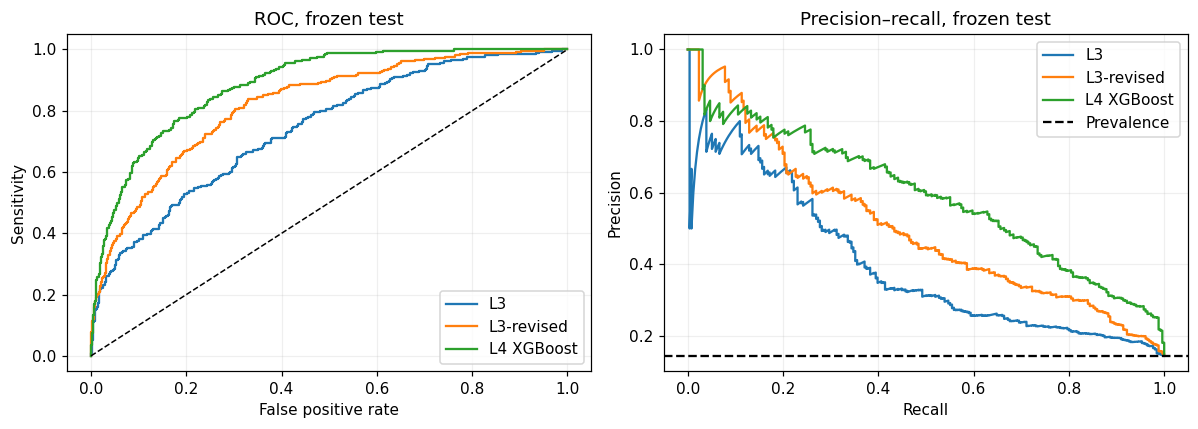

In [13]:
fair=[]
t = label_index.loc[X_imputed['test'].RecordID]
for col in ['saps_i','sofa']:
    mask=t[f'{col}_available'].eq(1).to_numpy()
    fair.append({'subset':col, 'n':int(mask.sum()),
        'score AUROC':roc_auc_score(y_test[mask],t.loc[mask,col]),
        'L4 AUROC':roc_auc_score(y_test[mask],p_test_l4[mask])})
display(pd.DataFrame(fair))
fig, axes=plt.subplots(1,2,figsize=(11,4))
for name, scores in predictions.items():
    fpr,tpr,_=roc_curve(y_test,scores); precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,label=name); axes[1].plot(recall,precision,label=name)
axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[1].axhline(y_test.mean(),color='k',ls='--',label='Prevalence')
axes[0].set(xlabel='False positive rate',ylabel='Sensitivity',title='ROC, frozen test')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall, frozen test')
for ax in axes: ax.legend()
fig.tight_layout();fig.savefig(FIGURE_DIR/'roc_pr_test.png');plt.show()

## 8. Clinical operating point, calibration and subgroups
The prespecified recall target reflects an illustrative priority to miss fewer deaths;
it is not a validated clinical policy. Test sensitivity is 0.785 and PPV 0.387, so most
alerts are still survivors. The next confusion matrix quantifies both missed deaths and
unnecessary reviews. Brier score and a reliability diagram assess probability quality;
ICU subgroup intervals are descriptive and some have few events.

,Not flagged,Flagged
Survived,1201,318
Died,55,201


Flagged 519/1775 (29.2%); misses 55/256 deaths.
Brier 0.0863; constant training-prevalence reference 0.1234


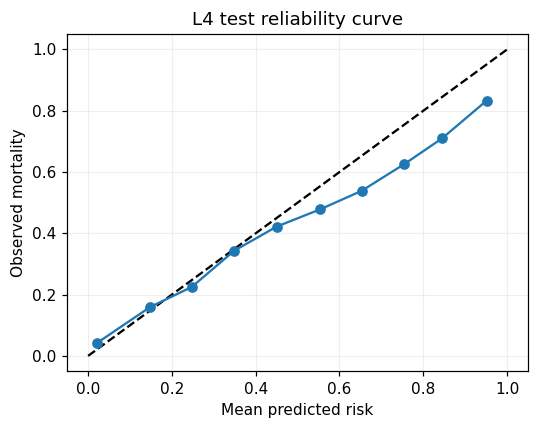

In [14]:
cm=confusion_matrix(y_test,p_test_l4>=threshold_l4,labels=[0,1])
display(pd.DataFrame(cm,index=['Survived','Died'],columns=['Not flagged','Flagged']))
flagged=int((p_test_l4>=threshold_l4).sum())
print(f'Flagged {flagged}/{len(y_test)} ({flagged/len(y_test):.1%}); misses {cm[1,0]}/{sum(y_test)} deaths.')
brier=brier_score_loss(y_test,p_test_l4)
assert np.isclose(brier,read_result('L4_calibration_and_subgroup.json')['calibration']['brier_score'])
print(f'Brier {brier:.4f}; constant training-prevalence reference {brier_score_loss(y_test,np.full(len(y_test),y_train.mean())):.4f}')
frac,mean=calibration_curve(y_test,p_test_l4,n_bins=10)
fig,ax=plt.subplots(figsize=(5,4));ax.plot([0,1],[0,1],'k--');ax.plot(mean,frac,'o-')
ax.set(xlabel='Mean predicted risk',ylabel='Observed mortality',title='L4 test reliability curve')
fig.tight_layout();fig.savefig(FIGURE_DIR/'calibration_test.png');plt.show()

In [15]:
subgroups=[]
for n,name in [(1,'Coronary'),(2,'Cardiac surgery recovery'),(3,'Medical'),(4,'Surgical')]:
    # ICU type is one-hot encoded. Do not interpret a single 0/1 column as codes 1–4.
    mask=raw_by_split['test'][f'static_icutype_{n}'].eq(1).to_numpy()
    a,lo,hi=bootstrap_ci(y_test[mask],p_test_l4[mask],roc_auc_score,n_bootstrap=N_BOOTSTRAP)
    subgroups.append({'ICU':name,'n':int(mask.sum()),'deaths':int(y_test[mask].sum()),'AUROC':a,'low':lo,'high':hi})
subgroup_table=pd.DataFrame(subgroups)
assert subgroup_table.n.sum()==len(y_test)
display(subgroup_table.round(4));subgroup_table.to_csv(TABLE_DIR/'icu_subgroups.csv',index=False)

,ICU,n,deaths,AUROC,low,high
0,Coronary,262,37,0.8541,0.7892,0.9085
1,Cardiac surgery recovery,370,19,0.9549,0.9129,0.9861
2,Medical,646,120,0.8365,0.7993,0.8709
3,Surgical,497,80,0.8966,0.8601,0.9290


Calibration is broadly closer to the diagonal at lower risks and over-confident in the
high-risk tail. A Brier score alone does not establish calibration. ICU subgroup AUROC
ranges from 0.837 to 0.955 here; the cardiac-surgery subset has only 19 deaths, making the
estimate uncertain. Sex and age-band fairness were not tested. Neither the subgroup table
nor a similar validation/test score establishes generalisation to other hospitals.

## 9. Explainability and validation ablations
The retained SHAP summary and case figures explain the frozen XGBoost model in log-odds.
They are model associations, not causal mechanisms or evidence for treatment decisions.
The plots are displayed from the saved artifacts; this default notebook does not claim
to recompute all test-set SHAP values. Regeneration scripts are under `code/baselines/`.

,feature_name,shap_importance
0,gcs__0_48h__last,0.694032
1,static_age_years,0.257569
2,urine__0_48h__total,0.140986
3,wbc__0_48h__slope_per_hour,0.098678
4,gcs__24_48h__last,0.097060
5,bun__0_48h__min,0.087892
6,mechvent__0_48h__time_span_hours,0.085402
7,urine__24_48h__total,0.083364
8,gcs__24_48h__median,0.082491
9,bun__24_48h__last,0.078977


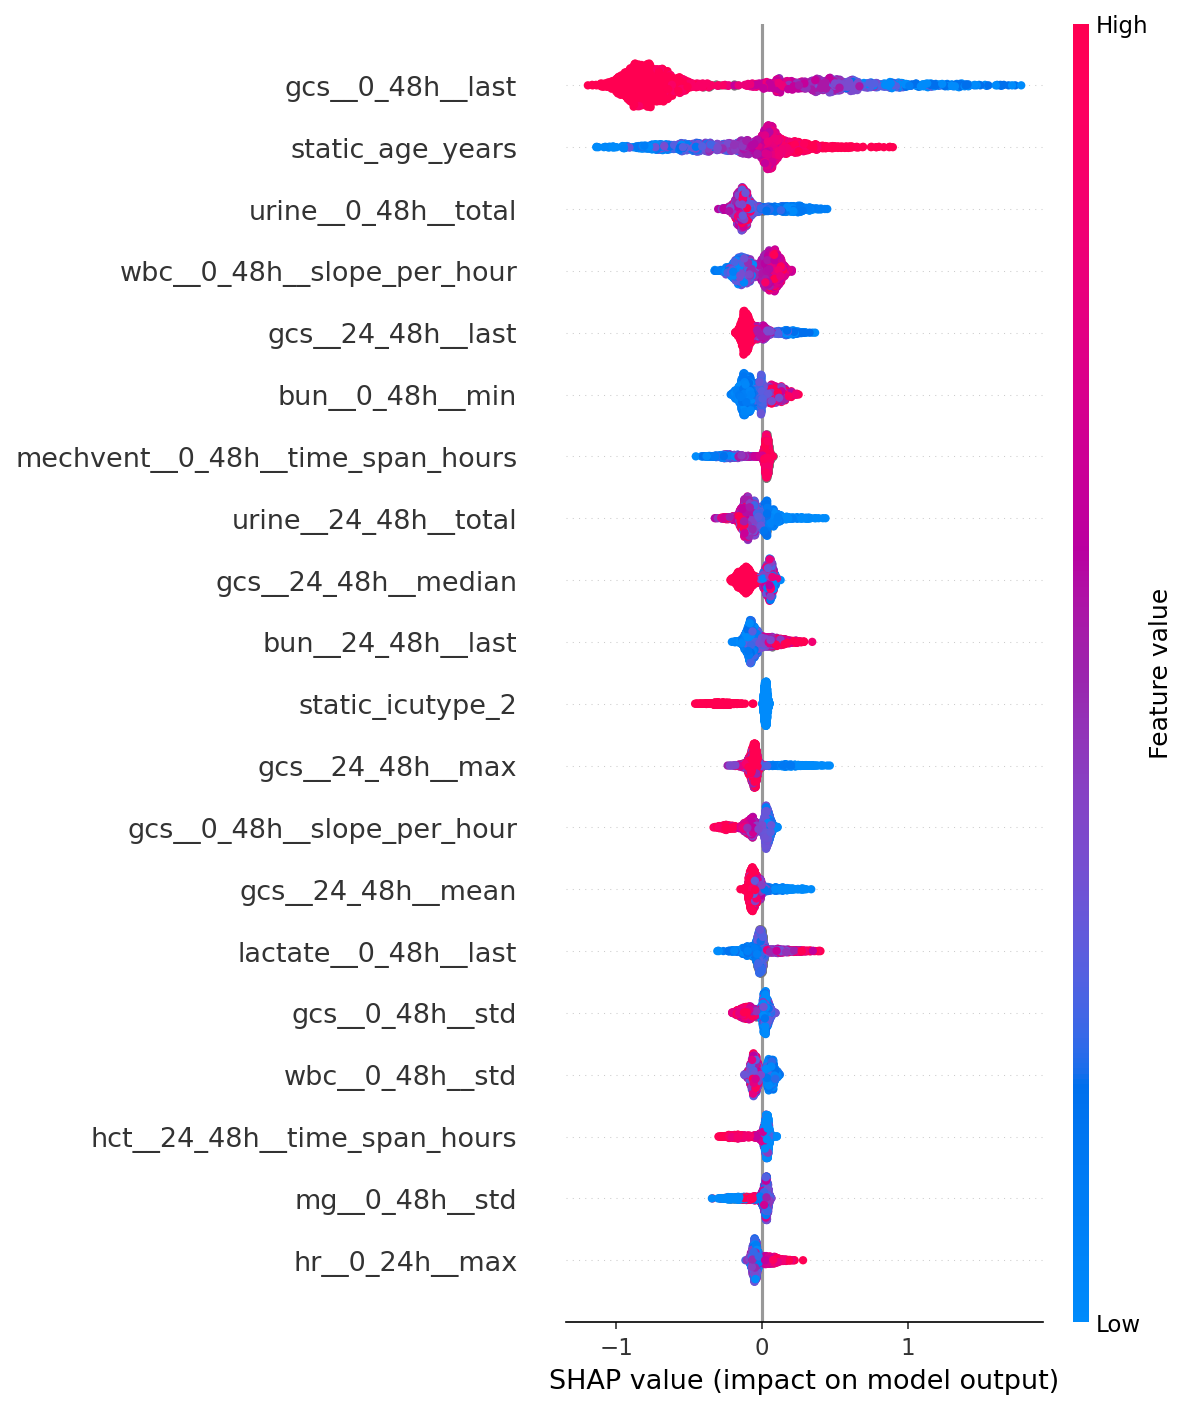

Saved case artifact keys: ['model', 'dataset', 'cases', '_note']


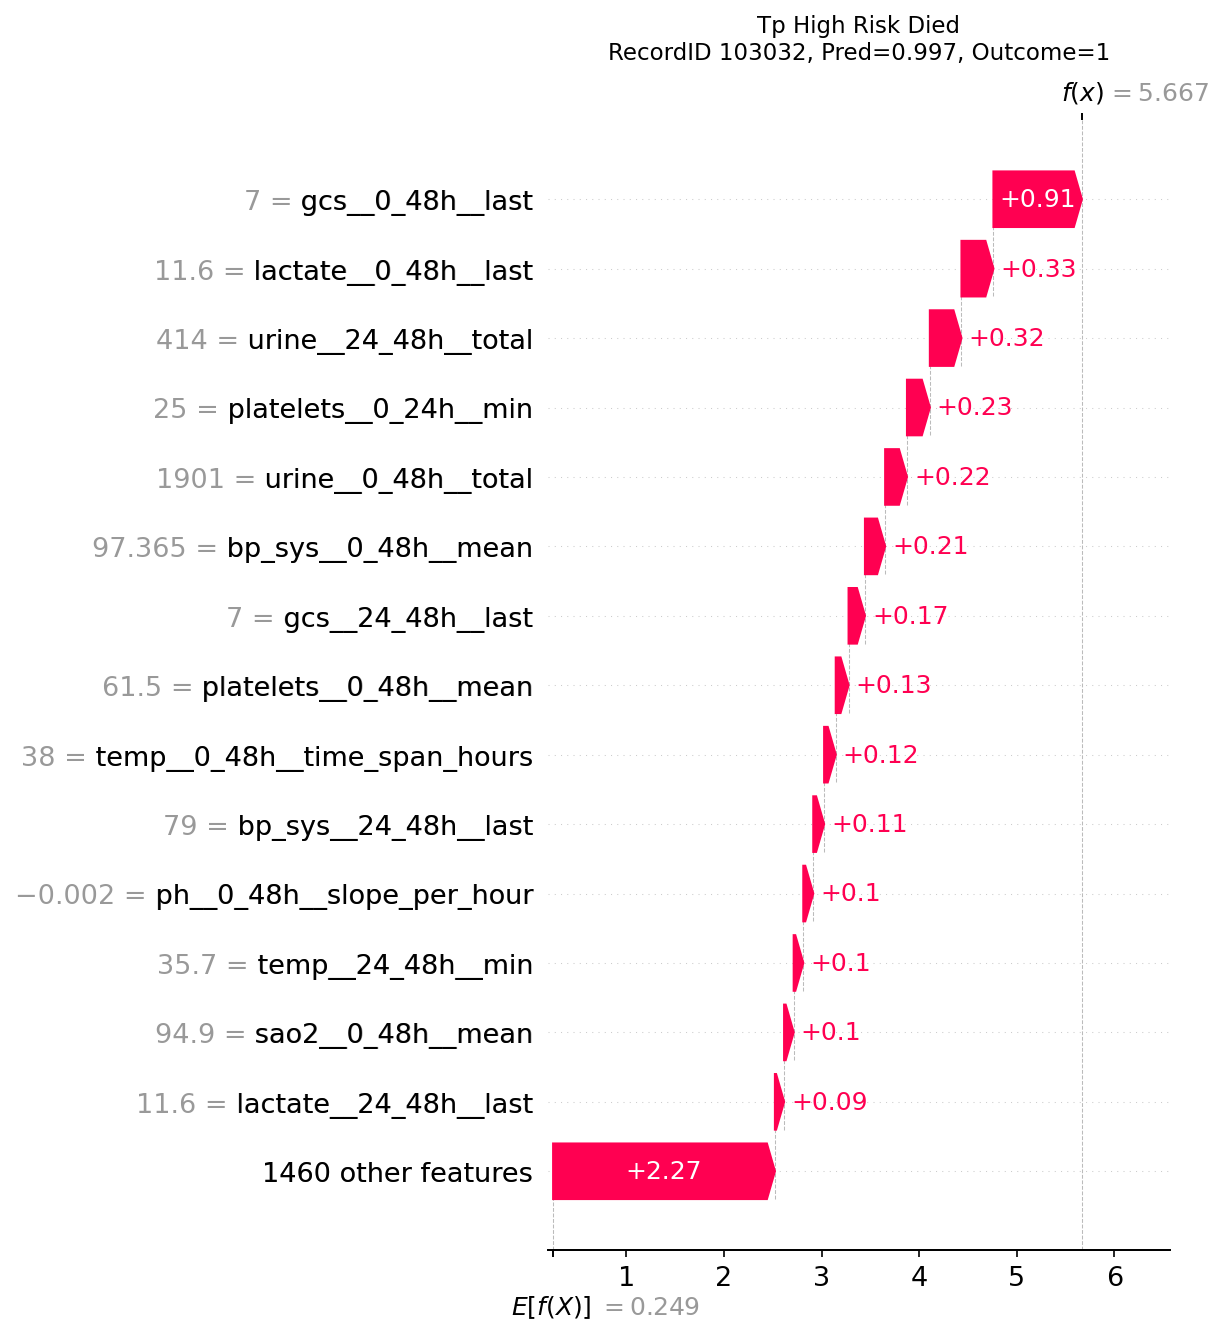

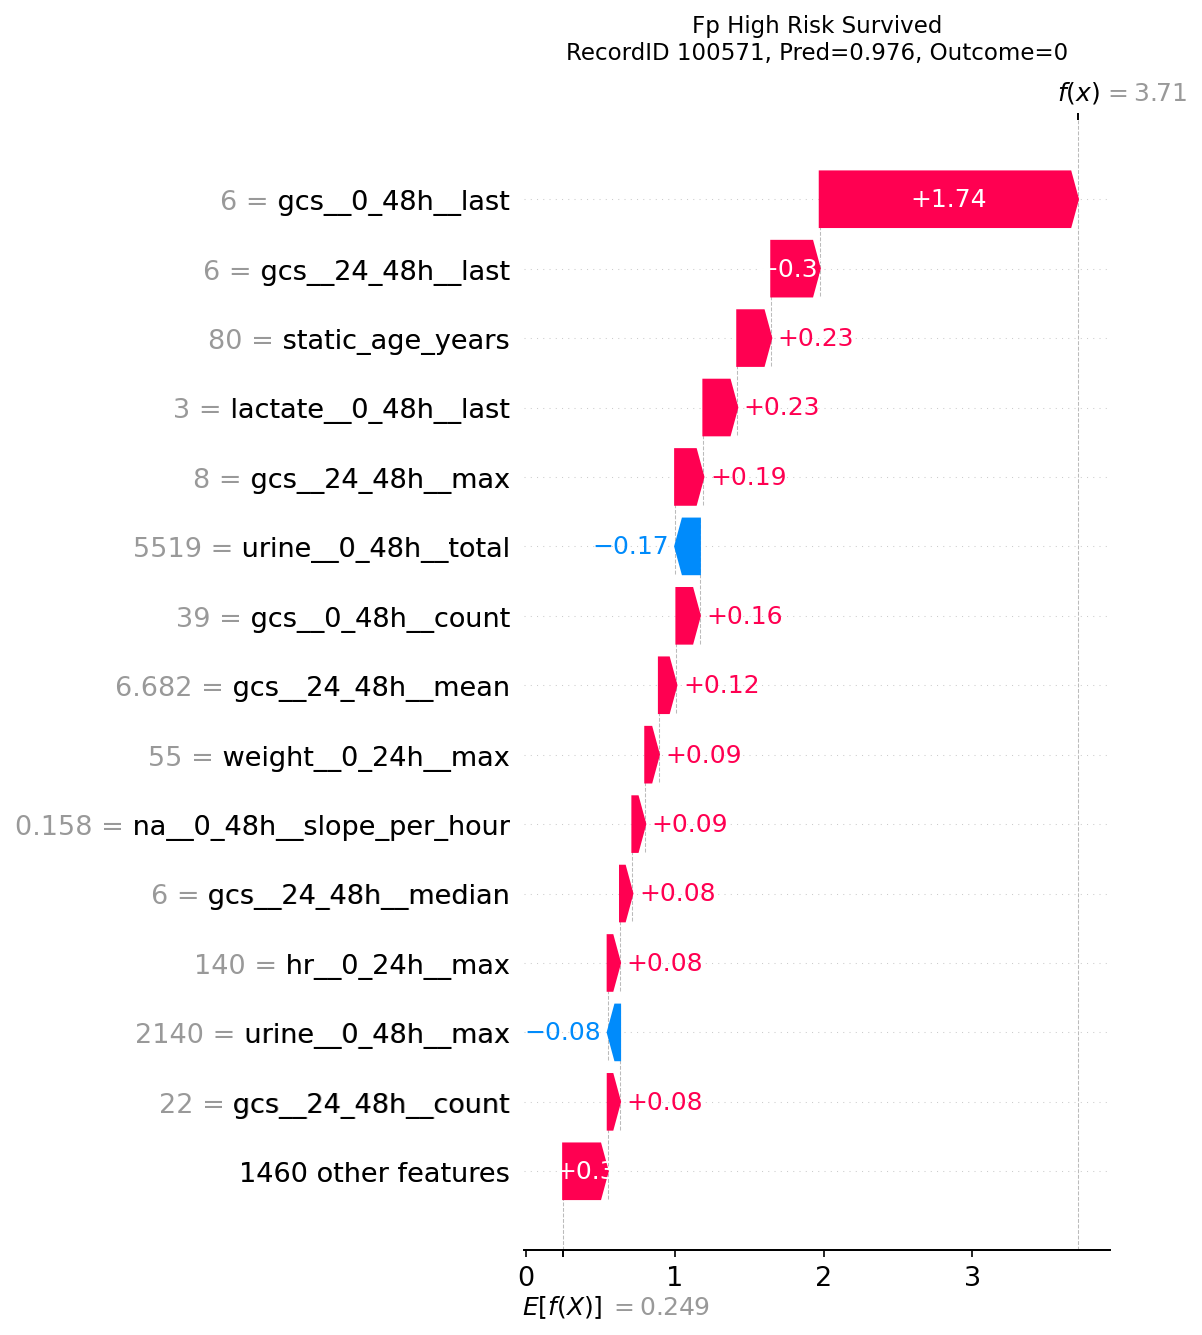

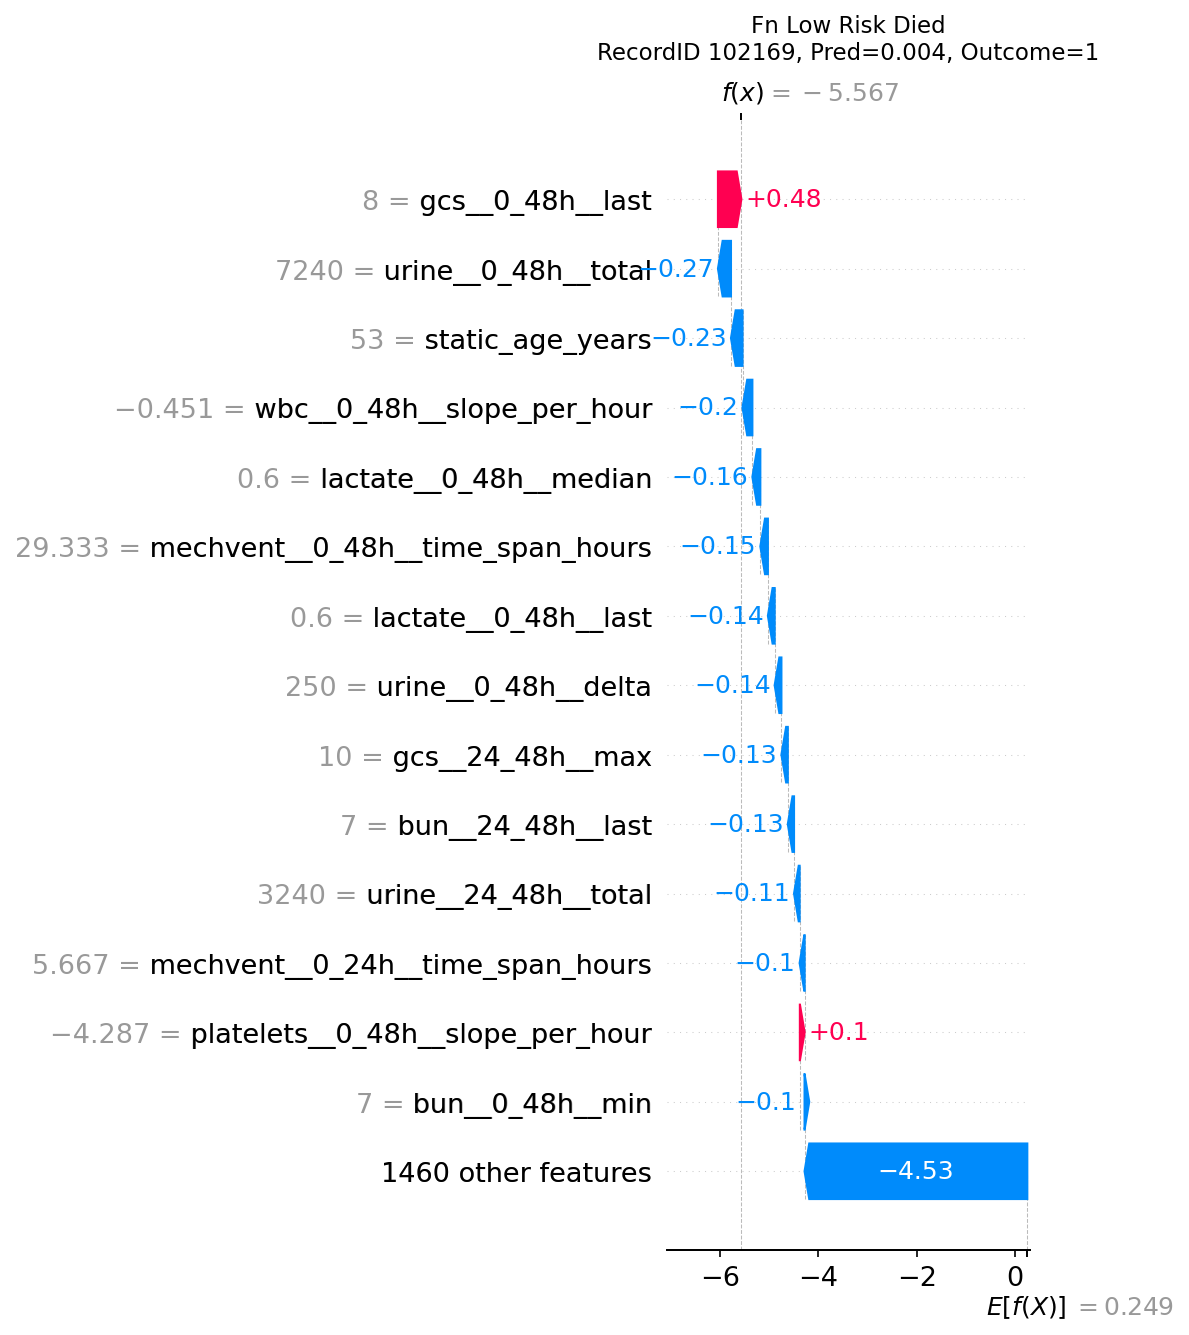

In [16]:
importance=pd.DataFrame(read_result('L4_feature_importance.json')['top_20_features'])
display(importance[['feature_name','shap_importance']].head(10))
display(Image(filename=str(ROOT/'results/figures/L4_shap_summary.png'),width=850))
case_result=read_result('L4_case_examples.json')
print('Saved case artifact keys:', list(case_result) if isinstance(case_result,dict) else 'case list')
for name in ['TP_high_risk_died','FP_high_risk_survived','FN_low_risk_died']:
    display(Image(filename=str(ROOT/f'results/figures/L4_shap_waterfall_{name}.png'),width=700))

Last GCS, age and urine output dominate the model's explanations. The false-positive case
shows that high predicted risk does not imply death; the false-negative case shows that
48-hour measurements can look reassuring before a later death. Sedation, post-ictal
states or subsequent deterioration are possible explanations, not verified facts for
these records. Caution is needed when translating model explanations into patient stories.

,k,trees_used,val_auroc,val_auprc
0,8,90,0.8129,0.4219
1,20,104,0.8349,0.4521
2,50,179,0.8566,0.4908
3,100,218,0.8607,0.5062
4,200,156,0.8616,0.5296
5,500,193,0.8673,0.5174
6,1474,275,0.8691,0.5321


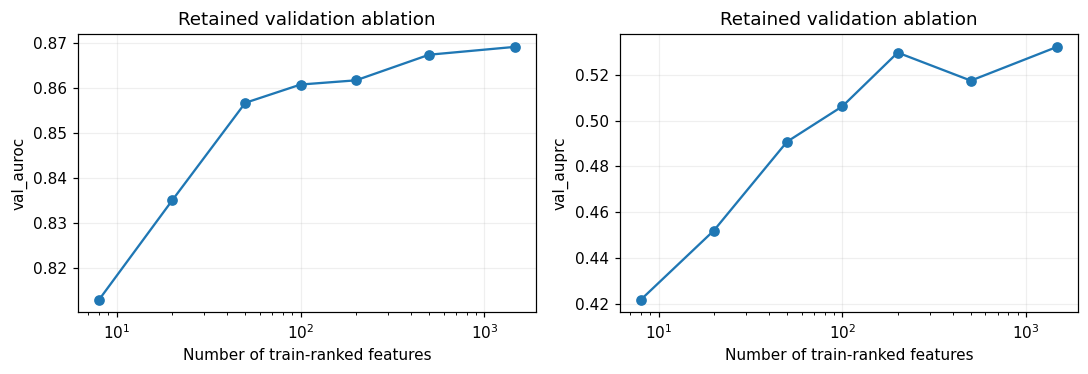

,n_features,train_auroc,val_auroc,val_auprc
A_original_gcs_min,8.0,0.733420,0.721710,0.306279
B_swap_gcs_min_to_last,8.0,0.813254,0.798451,0.422523
C_add_gcs_last_keep_min,9.0,0.821907,0.798971,0.415934
D_swap_urine_min_to_total,8.0,0.747247,0.743013,0.336900
E_both_swaps,8.0,0.819188,0.808149,0.437354


In [17]:
ablation=read_result('L4_feature_count_ablation.json')
# Show validation-only evidence without fitting to the test set.
ablation_table = pd.DataFrame(ablation['results'])
display(ablation_table[['k','trees_used','val_auroc','val_auprc']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ['val_auroc','val_auprc']):
    ax.plot(ablation_table.k, ablation_table[metric], 'o-')
    ax.set(xscale='log', xlabel='Number of train-ranked features', ylabel=metric,
           title='Retained validation ablation')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'feature_count_validation.png'); plt.show()
display(pd.DataFrame({k:v for k,v in read_result('L3_gcs_statistic_ablation.json').items() if k != '_note'}).T)

## 10. Discussion and limitations
Better summary statistics substantially improve a compact logistic model; the larger
GBDT adds further discrimination, but feature count and model family change together,
so this does not isolate the causal contribution of model complexity. Top-k validation
ablations suggest compact follow-up models, but choosing repeatedly on one validation
set also creates selection uncertainty.

Limits include one cohort and one split, no external or temporal validation, exclusion
of negative-LOS survivors, uncertain patient independence, possible informative
missingness and sedation effects, imperfect high-risk calibration, and no sex/age fairness
audit. The training AUROC near 1.0 indicates high capacity and a substantial generalisation
gap; decent held-out performance does not rule out overfitting. No paired significance
test or clinical utility study was performed. The original public challenge used other
evaluation sets, preventing direct “beats the challenge” claims.

Future work: external and temporal validation, train/validation-fitted recalibration,
decision-curve analysis, patient-level grouping where identifiers exist, fairness auditing,
and independently evaluated compact models. This submission is research evidence, not
a clinical deployment.

## 11. Outputs and verification
Tables and verification records are saved to `results/notebook/`; the five newly rendered
plots to `results/figures/notebook/`; fitted logistic pipelines and their feature/threshold
metadata to `models/notebook/`. The [output index](results/notebook/README.md) links all
published files. The output manifest records their SHA-256 hashes. The reviewed tree
models remain at their original paths under `models/`. Replaying these fixed choices is
a reproducibility check, not a fresh estimate after development.

A default rerun refreshes these committed reproduction outputs. Optional new development
fits stay in the ignored `artifacts/notebook/` directory until deliberately reviewed.

In [18]:
pd.DataFrame(review_checks).to_csv(TABLE_DIR/'reviewed_metric_checks.csv',index=False)
summary={'status':'PASS','cohort':len(labels),'features':len(features),'test_n':len(y_test),
    'snapshot_files_verified':len(checks),'bootstrap_resamples':N_BOOTSTRAP,
    'threshold':float(threshold_l4),'l4_test_metrics':{k:float(v) for k,v in l4_metrics.items()},
    'brier':float(brier),'reviewed_metric_checks':review_checks,'environment':versions,
    'full_search_executed':RUN_FULL_SEARCH,'l4_retraining_executed':RETRAIN_L4}
(MODEL_DIR/'model_metadata.json').write_text(json.dumps({
    'source_notebook': 'In_Hospital_Death.ipynb', 'target': 'In-hospital_death',
    'input': 'engineered per-stay features before imputation; use each bundle feature list',
    'environment': versions, 'models': model_metadata,
}, indent=2) + chr(10))
published_files = [
    *[FIGURE_DIR/name for name in ['eda_measurement_coverage.png', 'eda_outcomes_training.png',
        'roc_pr_test.png', 'calibration_test.png', 'feature_count_validation.png']],
    *[TABLE_DIR/name for name in ['gcs_statistic_development.csv', 'ladder_test.csv',
        'icu_subgroups.csv', 'reviewed_metric_checks.csv']],
    MODEL_DIR/'L3_pipeline.joblib', MODEL_DIR/'L3-revised_pipeline.joblib',
    MODEL_DIR/'model_metadata.json', RESULT_DIR/'verification.json',
]
summary['published_output_paths'] = [p.relative_to(ROOT).as_posix() for p in published_files]
(RESULT_DIR/'verification.json').write_text(json.dumps(summary,indent=2) + chr(10))
output_manifest = {
    'source_notebook': 'In_Hospital_Death.ipynb',
    'description': 'Default CPU replay outputs; historical L4 artifacts and frozen inputs are separate.',
    'files': {p.relative_to(ROOT).as_posix(): {
        'bytes': p.stat().st_size, 'sha256': hashlib.sha256(p.read_bytes()).hexdigest()
    } for p in published_files},
}
(RESULT_DIR/'manifest.json').write_text(json.dumps(output_manifest,indent=2) + chr(10))
display(pd.Series({k:v for k,v in summary.items() if k not in ['environment','reviewed_metric_checks','l4_test_metrics']}))
print('PASS: snapshot verified, declared model recipes reproduced, tables and plots saved.')

status                                                                  PASS
cohort                                                                 11833
features                                                                1474
test_n                                                                  1775
snapshot_files_verified                                                   16
bootstrap_resamples                                                     1000
threshold                                                           0.108227
brier                                                               0.086268
full_search_executed                                                   False
l4_retraining_executed                                                 False
published_output_paths     [results/figures/notebook/eda_measurement_cove...
dtype: object

PASS: snapshot verified, declared model recipes reproduced, tables and plots saved.
